# Particle sets and their potential

Run all cells. Change `rho`, `phase` or `show_ids` below and run again.
The plots show **initial positions**, without integrating trajectories.

- **40 particles:** original IDs 1–40, distributed along eight rays from the cell center. Their Poincare sections sample the main oval structure observed in the historical study; these plots show their star-shaped initial positions.
- **84 particles:** the 40 star points, 8 additional probes (IDs 41–48) and 36 neighboring points (IDs 49–84).
- **8 candidate chaotic particles:** selected IDs 12, 15, 18, 21, 24, 27, 30 and 33, with their original positions and colors. Their chaotic character has not been verified for the reflected potential.
- **8 candidate periodic particles:** selected IDs 1, 2, 60, 64, 65, 72, 76 and 83 from the 84-particle set, with their original positions and colors. Their periodicity and periods have not been verified for the reflected potential.

The radius is measured in base-cell widths: `rho = 0.30` reaches gyroaveraging unchanged (0.054 m for a 0.18 m cell). Historical outputs and their old radius convention are preserved separately.

All panels use the main campaign's **reflected, gyroaveraged potential**, with magnetic field 1.5 T, constant field 0 and temporal mode 15 from `PHI_2.h5`. The displayed square is $[0,1]^2$; the spatial extension has period 2 and does not confine trajectories to this square.

In [1]:
rho = 0.30        # Radius in base-cell widths; passed directly to gyroaveraging.
phase = 0.0       # Fraction of one forcing cycle, from 0 to 1.
show_ids = False  # Set True to label particles with their original IDs.
export_thesis_figure = False  # Copy the verified first-set figure to the sibling thesis when True.
campaign_name = "main-20261116-direct-rho"  # Keep corrected outputs separate from historical runs.


In [2]:
from pathlib import Path
from hashlib import sha256
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

# Works when launched from the repository root or its notebooks directory.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/potential/potential.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the GC2D_codigo repository.")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from dynamics.gc import GuidingCenterDynamics
from studies.main_campaign import RHOS, SOURCE_SHA256, load_field

# Each dataset is read from its own independent JSON file.
files = ["original_40.json", "expanded_84.json",
         "chaotic_candidates.json", "periodic_candidates_8.json"]
datasets = [json.loads((root / "data/particles" / name).read_text()) for name in files]
for dataset in datasets:
    assert dataset["source_sha256"] == SOURCE_SHA256
    assert len(dataset["particles"]) == dataset["particle_count"]
    expected_count = 0 if dataset["status"] == "pending" else dataset["target_particle_count"]
    assert dataset["particle_count"] == expected_count

# The first dataset contains exactly the original forty star particles.
assert [p["id"] for p in datasets[0]["particles"]] == list(range(1, 41))
assert datasets[0]["particles"] == datasets[1]["particles"][:40]

# The third dataset retains the selected original particle records.
selected_ids = [12, 15, 18, 21, 24, 27, 30, 33]
assert [p["id"] for p in datasets[2]["particles"]] == selected_ids
assert datasets[2]["particles"] == [datasets[0]["particles"][i - 1] for i in selected_ids]

# The fourth dataset retains two original particles and six added neighbors.
periodic_ids = [1, 2, 60, 64, 65, 72, 76, 83]
expanded_by_id = {p["id"]: p for p in datasets[1]["particles"]}
assert [p["id"] for p in datasets[3]["particles"]] == periodic_ids
assert datasets[3]["particles"] == [expanded_by_id[i] for i in periodic_ids]
assert datasets[3]["selection"]["verified_for_reflected_potential"] is False

field = load_field(root / "data/potential/V1/PHI_2.h5")  # Verifies SHA-256.
metadata = field.metadata
if not any(np.isclose(rho, value, rtol=0, atol=1e-12) for value in RHOS):
    raise ValueError("Choose rho from 0.00 to 0.50 in steps of 0.05.")
if not 0 <= phase <= 1:
    raise ValueError("Choose a phase between 0 and 1.")

# rho already uses normalized coordinates; rho_m is provenance only.
rho_m = rho * metadata.spatial_scale
dynamics = GuidingCenterDynamics(field, rho=rho, B=1.5)
assert dynamics.rho == rho
output_dir = root / "notebooks/developements/main_reflected_campaign" / campaign_name / "postprocessing/chapter4/current"
output_dir.mkdir(parents=True, exist_ok=True)
hamiltonian = dynamics.hamiltonian_potential
period = 1 / float(field.frequencies[0])
origin_m = np.array([metadata.source_x[0], metadata.source_y[0]])

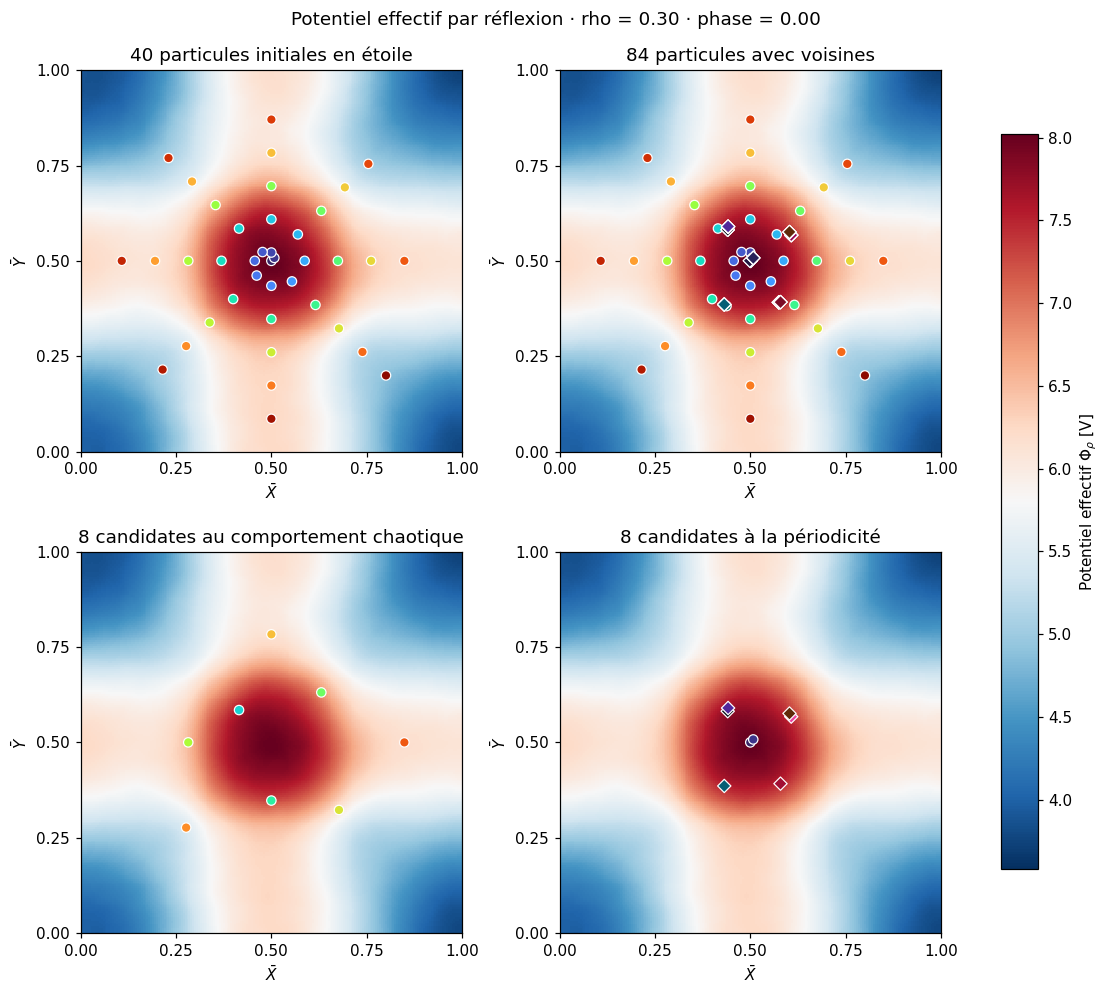

In [3]:
axis = np.linspace(0, 1, 201)
x, y = np.meshgrid(axis, axis)

# H = T * Phi_rho / (B * L**2); recover the effective potential in volts.
voltage_scale = dynamics.B * metadata.spatial_scale**2 / metadata.time_scale

def potential_at(cycle_phase):
    return voltage_scale * hamiltonian.evaluate(cycle_phase * period, x, y)

potential = potential_at(phase)
# Fixed color limits over the complete cycle (one temporal Fourier mode).
p0, p25, p50 = (potential_at(p) for p in (0, 0.25, 0.5))
mean = (p0 + p50) / 2
amplitude = np.hypot((p0 - p50) / 2, p25 - mean)
vmin, vmax = float(np.min(mean - amplitude)), float(np.max(mean + amplitude))
np.testing.assert_allclose(potential_at(1), p0, rtol=1e-11, atol=1e-12)

# Figure text follows the thesis convention: French in both editions.
figure_titles = {
    "original_40": "40 particules initiales en étoile",
    "expanded_84": "84 particules avec voisines",
    "chaotic_candidates": "8 candidates au comportement chaotique",
    "periodic_candidates_8": "8 candidates à la périodicité",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for ax, dataset in zip(axes.flat, datasets):
    particles = dataset["particles"]
    ids = np.array([p["id"] for p in particles])
    positions_m = np.array([p["position_m"] for p in particles]).reshape(-1, 2)
    xy = (positions_m - origin_m) / metadata.spatial_scale
    colors = np.array([p["color"] for p in particles])
    neighbors = np.array([p.get("kind") == "neighbor" for p in particles], dtype=bool)
    # Historical cell widths differ by rounding; physical positions remain exact.
    fractions = np.array([p["cell_fraction"] for p in particles]).reshape(-1, 2)
    np.testing.assert_allclose(xy, fractions, rtol=0, atol=1e-12)
    background = ax.pcolormesh(x, y, potential, shading="auto", cmap="RdBu_r",
                              vmin=vmin, vmax=vmax, rasterized=True)
    for mask, marker in ((~neighbors, "o"), (neighbors, "D")):
        ax.scatter(*xy[mask].T, c=colors[mask], s=38, marker=marker,
                   edgecolors="white", linewidths=0.8, zorder=3)
    if show_ids:
        for pid, point in zip(ids, xy):
            ax.annotate(str(pid), point, xytext=(4, 4), textcoords="offset points",
                        fontsize=7, bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
    if dataset["status"] == "pending":
        ax.text(0.5, 0.5, "Conditions initiales périodiques\nnon encore vérifiées", ha="center", va="center",
                transform=ax.transAxes, bbox=dict(facecolor="white", alpha=0.95, edgecolor="0.7", pad=12))
    title = figure_titles[dataset["dataset_id"]]
    ax.set(title=title, xlabel=r"$\bar X$", ylabel=r"$\bar Y$",
           xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])

fig.suptitle(f"Potentiel effectif par réflexion · rho = {rho:.2f} · phase = {phase:.2f}")
fig.colorbar(background, ax=axes, shrink=0.8, label=r"Potentiel effectif $\Phi_\rho$ [V]")
for extension in ("pdf", "png"):
    fig.savefig(output_dir / f"particle_sets_potential_fr.{extension}", dpi=300, bbox_inches="tight")
plt.show()

## First dataset: 40 original particles

This individual view shows IDs 1–40 with their original positions and colors. It is the figure used beside the first dataset's explanation in the thesis.
The PDF, PNG and provenance record are saved under the new campaign's `postprocessing/chapter4/current/` directory. Set `export_thesis_figure = True` to copy them to the existing sibling `TFM_redaccion/figuras/` directory after validation. Historical figures were archived before this update.


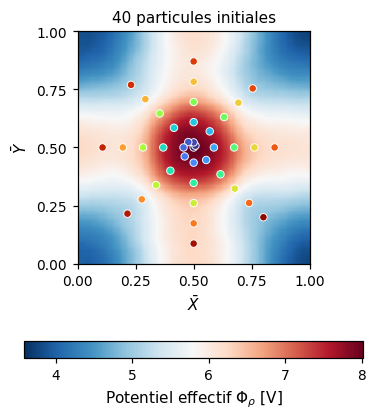

In [4]:
# Reuse the exact potential and cycle-wide color scale of the overview.
first_particles = datasets[0]["particles"]
first_positions = np.array([p["position_m"] for p in first_particles])
first_xy = (first_positions - origin_m) / metadata.spatial_scale
with plt.rc_context({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
                     "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "pdf.fonttype": 42, "savefig.facecolor": "white"}):
    first_fig, first_ax = plt.subplots(figsize=(3.4, 3.7), layout="constrained")
    first_background = first_ax.pcolormesh(
        x, y, potential, shading="auto", cmap="RdBu_r",
        vmin=vmin, vmax=vmax, rasterized=True,
    )
    first_ax.scatter(*first_xy.T, c=[p["color"] for p in first_particles],
                     s=24, edgecolors="white", linewidths=0.6, zorder=3)
    if show_ids:
        for particle, point in zip(first_particles, first_xy):
            first_ax.annotate(str(particle["id"]), point, xytext=(3, 3),
                              textcoords="offset points", fontsize=6)
    first_ax.set(title="40 particules initiales", xlabel=r"$\bar X$", ylabel=r"$\bar Y$",
                 xlim=(0, 1), ylim=(0, 1), aspect="equal")
    first_ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    first_ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    first_fig.colorbar(first_background, ax=first_ax, orientation="horizontal",
                       pad=0.10, label=r"Potentiel effectif $\Phi_\rho$ [V]")
    figure_record = {
        "dataset": "GC2D_codigo/data/particles/original_40.json",
        "dataset_sha256": sha256((root / "data/particles/original_40.json").read_bytes()).hexdigest(),
        "particle_ids": [p["id"] for p in first_particles],
        "source_sha256": SOURCE_SHA256, "spatial_extension": "reflected",
        "rho_study": rho, "rho_runtime": dynamics.rho, "rho_m": rho_m,
        "rho_convention": "base_cell_widths", "spatial_scale_m": metadata.spatial_scale,
        "phase": phase, "magnetic_field_T": dynamics.B, "potential_unit": "V",
        "color_limits": [vmin, vmax], "figure_language": "fr", "trajectory_integrations": 0,
    }
    destinations = [output_dir]
    if export_thesis_figure:
        thesis_root = root.parent / "TFM_redaccion"
        if not (thesis_root / "main.tex").is_file() or not (thesis_root / "figuras").is_dir():
            raise FileNotFoundError("The existing sibling thesis directory is required for export.")
        destinations.append(thesis_root / "figuras")
    for destination in destinations:
        for extension in ("pdf", "png"):
            first_fig.savefig(destination / f"primer_conjunto_40_fr.{extension}",
                              dpi=300, bbox_inches="tight", pad_inches=0.04)
        (destination / "primer_conjunto_40.json").write_text(
            json.dumps(figure_record, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    plt.show()


Circles mark original particles; diamonds identify added neighbors, including the six selected in the fourth set. Some neighbors are too close to distinguish at the full-square scale.

Each active set is stored independently under `data/particles/`: `original_40.json`, `expanded_84.json`, `chaotic_candidates.json` and `periodic_candidates_8.json`.
The historical `original_48.json`, `chaotic_candidates_7.json`, `chaotic_candidates_8.json` and `periodic_8.json` remain available for reproducing earlier selections; none is one of the four panels.
The historical `periodic_8.json` records IDs 85–92 and their numerically verified minimum periods at `rho = 0.30`. Those checks apply to that historical selection only; the current fourth set records a user selection whose periodicity remains unverified.

These JSON files and this notebook belong in Git. They are outside the notebook Backblaze synchronization, which is limited to `notebooks/developements/`. The notebook reads the local measured potential and does not need development or thesis files, launch Modal jobs or upload data.
